<a href="https://colab.research.google.com/github/vishwakumar1311/Bigram/blob/main/Bigram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import pandas as pd

In [ ]:
data = open("/content/drive/MyDrive/names.txt")

In [ ]:
import torch.nn.functional as F


In [ ]:
data.seek(0)
names_data = data.read().splitlines()
print(names_data)

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn', 'abigail', 'emily', 'elizabeth', 'mila', 'ella', 'avery', 'sofia', 'camila', 'aria', 'scarlett', 'victoria', 'madison', 'luna', 'grace', 'chloe', 'penelope', 'layla', 'riley', 'zoey', 'nora', 'lily', 'eleanor', 'hannah', 'lillian', 'addison', 'aubrey', 'ellie', 'stella', 'natalie', 'zoe', 'leah', 'hazel', 'violet', 'aurora', 'savannah', 'audrey', 'brooklyn', 'bella', 'claire', 'skylar', 'lucy', 'paisley', 'everly', 'anna', 'caroline', 'nova', 'genesis', 'emilia', 'kennedy', 'samantha', 'maya', 'willow', 'kinsley', 'naomi', 'aaliyah', 'elena', 'sarah', 'ariana', 'allison', 'gabriella', 'alice', 'madelyn', 'cora', 'ruby', 'eva', 'serenity', 'autumn', 'adeline', 'hailey', 'gianna', 'valentina', 'isla', 'eliana', 'quinn', 'nevaeh', 'ivy', 'sadie', 'piper', 'lydia', 'alexa', 'josephine', 'emery', 'julia', 'delilah', 'arianna', 'vivian', 'kaylee', 'sophie', 'brielle', 'madeline', 'peyton', 'ryle

In [ ]:
names_data = ['.'+word+'.' for word in names_data]
names_data

['.emma.',
 '.olivia.',
 '.ava.',
 '.isabella.',
 '.sophia.',
 '.charlotte.',
 '.mia.',
 '.amelia.',
 '.harper.',
 '.evelyn.',
 '.abigail.',
 '.emily.',
 '.elizabeth.',
 '.mila.',
 '.ella.',
 '.avery.',
 '.sofia.',
 '.camila.',
 '.aria.',
 '.scarlett.',
 '.victoria.',
 '.madison.',
 '.luna.',
 '.grace.',
 '.chloe.',
 '.penelope.',
 '.layla.',
 '.riley.',
 '.zoey.',
 '.nora.',
 '.lily.',
 '.eleanor.',
 '.hannah.',
 '.lillian.',
 '.addison.',
 '.aubrey.',
 '.ellie.',
 '.stella.',
 '.natalie.',
 '.zoe.',
 '.leah.',
 '.hazel.',
 '.violet.',
 '.aurora.',
 '.savannah.',
 '.audrey.',
 '.brooklyn.',
 '.bella.',
 '.claire.',
 '.skylar.',
 '.lucy.',
 '.paisley.',
 '.everly.',
 '.anna.',
 '.caroline.',
 '.nova.',
 '.genesis.',
 '.emilia.',
 '.kennedy.',
 '.samantha.',
 '.maya.',
 '.willow.',
 '.kinsley.',
 '.naomi.',
 '.aaliyah.',
 '.elena.',
 '.sarah.',
 '.ariana.',
 '.allison.',
 '.gabriella.',
 '.alice.',
 '.madelyn.',
 '.cora.',
 '.ruby.',
 '.eva.',
 '.serenity.',
 '.autumn.',
 '.adeline.',
 

In [ ]:
pair_count ={}
for name in names_data:

    for ch1,ch2 in zip(name, name[1:]):
      pair_count[(ch1,ch2)] = pair_count.get((ch1,ch2),0)+1


In [ ]:
sorted(pair_count.items(), key= lambda x: -x[1])

[(('n', '.'), 6763),
 (('a', '.'), 6640),
 (('a', 'n'), 5438),
 (('.', 'a'), 4410),
 (('e', '.'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('.', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('.', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '.'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('.', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '.'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('.', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '.'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('.', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('.', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('.', 'l'), 1572),
 (('.', 'c'), 1542),
 (('.', 'e'), 1531),
 (('j', 'a'), 1473),
 (('r', '.'), 1377),
 (('n', 'e'),

In [ ]:
d= torch.zeros((3,5),dtype= torch.int32)


In [ ]:
letters=sorted(list(set(''.join(names_data))))
print(letters)

['.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [ ]:
numbers= [i for i in range(0,len(letters)+1)]
stoi = {letter:number for letter,number in zip(letters,numbers)}
itos = {number:letter for letter,number in zip(letters,numbers)}
itos

{0: '.',
 1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z'}

In [ ]:
stoi

{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [ ]:
from os import XATTR_CREATE
from re import X
def build_dataset(words):
  block_size =3
  X,Y =[],[]

  for w in words:
    # print(w)
    context= [0]*block_size
    for ch in w+ '.':
      ix= stoi[ch]
      X.append(context)
      Y.append(ix)
      # print(''.join(itos[i] for i in context), '--->', itos[ix])
      context= context[1:]+[ix]
      # print('context---> ',context)

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X,Y
import random

random.seed(42)
random.shuffle(names_data)
n1= int(0.8*len(names_data))
n2= int(0.9*len(names_data))
Xtr,Ytr= build_dataset(names_data[:n1])
Xdev,Ydev= build_dataset(names_data[n1:n2])
Xte,Yte= build_dataset(names_data[n2:])

In [ ]:
X.shape,Y.shape

(torch.Size([292212, 3]), torch.Size([292212]))

#Riyal

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
g= torch.Generator().manual_seed(2147483647)
c = torch.randn((27,10),generator=g,dtype=float)
w1 = torch.randn((30,300),generator=g,dtype=float)
b1 = torch.randn(300,generator=g,dtype=float)
w2 = torch.randn((300,27),generator=g,dtype=float)
b2 = torch.randn(27,generator=g,dtype=float)
parameters = [c,w1,b1,w2,b2]

In [ ]:
for p in parameters:
  p.requires_grad = True

In [ ]:
lre=torch.linspace(-3,0,1000)
lrs= 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [ ]:
lr1=[]
lossi=[]
step=[]

In [ ]:
lr1=[]
lossi=[]
step=[]

for i in range(70000):
  xi = torch.randint(0, Xtr.shape[0], (64,))
  emb= c[Xtr[xi]]
  h = torch.tanh(emb.view(-1, 3* c.shape[1])@w1 +b1) # block_size * c.shape[1] = 3 * 2 = 6
  logits = h @ w2 +b2
  loss= F.cross_entropy(logits,Ytr[xi])
  # print(loss.item())
  for p in parameters:
    p.grad = None
  loss.backward()
  l=0.001
  for p in parameters:
    p.data += -l*p.grad
  # lr1.append(lre[i])
  step.append(i)
  lossi.append(loss.log10().item())
print(loss.item())

1.6156717161200629


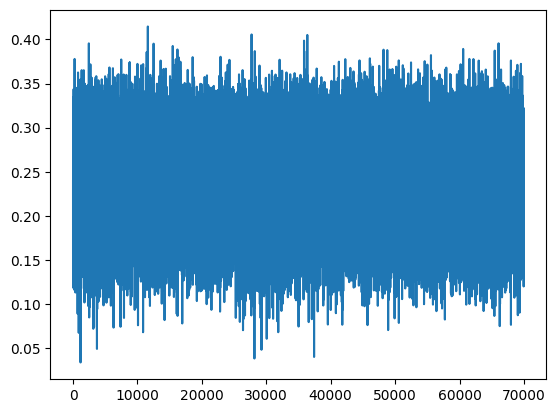

In [ ]:
plt.plot(step,lossi)

In [ ]:
emb= c[Xtr]
h = torch.tanh(emb.view(-1, 3 * c.shape[1])@w1 +b1)
logits = h @ w2 +b2
loss= F.cross_entropy(logits,Ytr)
loss

tensor(1.7505, dtype=torch.float64, grad_fn=<NllLossBackward0>)

In [ ]:
emb= c[Xdev]
h = torch.tanh(emb.view(-1, 3 * c.shape[1])@w1 +b1)
logits = h @ w2 +b2
loss= F.cross_entropy(logits,Ydev)
loss

tensor(1.8130, dtype=torch.float64, grad_fn=<NllLossBackward0>)

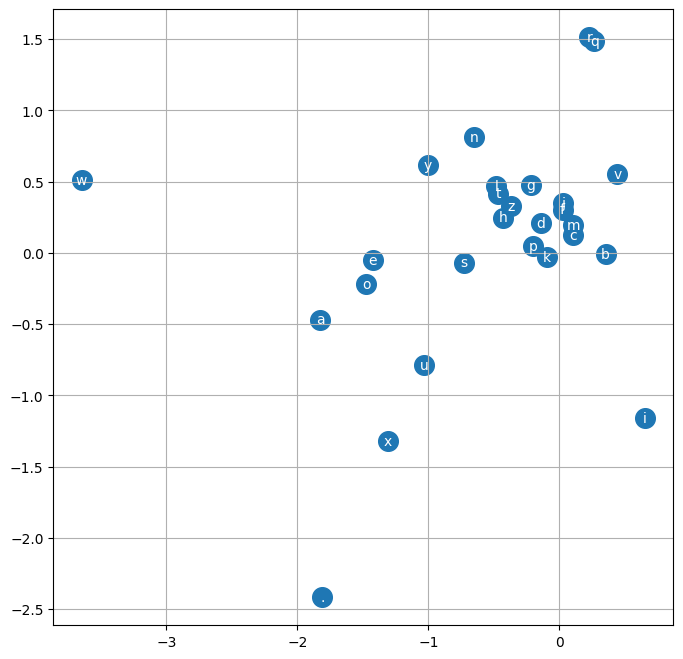

In [ ]:
plt.figure(figsize=(8,8))
plt.scatter(c[:,0].detach(), c[:,1].detach(), s=200)
for i, char in itos.items():
  plt.text(c[i,0].item(), c[i,1].item(), char, ha="center", va="center", color='white')
plt.grid('on')
plt.show()

In [ ]:
#sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out = []
  context = [0]*3
  is_first_char = True
  while True:
    emb = c[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ w1 + b1)
    logits = h @ w2 + b2
    probs = F.softmax(logits, dim=1)

    if is_first_char:
        probs[:, 0] = 0.0
        # Re-normalize probabilities so they still sum to 1
        probs = probs / probs.sum(dim=1, keepdim=True)
        is_first_char = False

    # Removed generator=g
    ix = torch.multinomial(probs, num_samples=1).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break
  print(''.join(itos[i] for i in out))


akila.
amin.
augan.
lewelde.
ivyana.
jordana.
reen.
sajoselyn.
rea.
her.
kenne.
adniellen.
mok.
azarie.
sh.
dameimy.
laytikahnoisiah.
aubri.
raclel.
gen.
